# Shrinkage smooths

The penalty of a standard smooth only penalizes wiggliness, so some functions are not
penalized at all: for a [`ThinPlateSpline`][pymgcv.basis_functions.ThinPlateSpline] or
[`CubicSpline`][pymgcv.basis_functions.CubicSpline] of one variable, these are the
linear functions. Even with a very large smoothing parameter, such a term is shrunk to
a straight line, and never removed from the model.

Shrinkage smooths add a small penalty on these functions too, so that a term can be
shrunk to zero. This makes them useful for term selection: the effect of a covariate
that does not matter is shrunk away. In this example, `y` depends on `x0`, while `x1`
is irrelevant.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pymgcv.plot as gplt
from pymgcv.basis_functions import ThinPlateSpline
from pymgcv.gam import GAM
from pymgcv.terms import S

rng = np.random.default_rng(0)
n = 200
x0 = rng.uniform(0, 1, n)
x1 = rng.uniform(0, 1, n)
y = np.sin(2 * np.pi * x0) + rng.normal(scale=0.3, size=n)
data = pd.DataFrame({"x0": x0, "x1": x1, "y": y})

We fit the same model with standard thin plate splines and with their shrinkage
version, `ThinPlateSpline(shrinkage=True)`, and plot the partial effects with their
effective degrees of freedom (EDF).

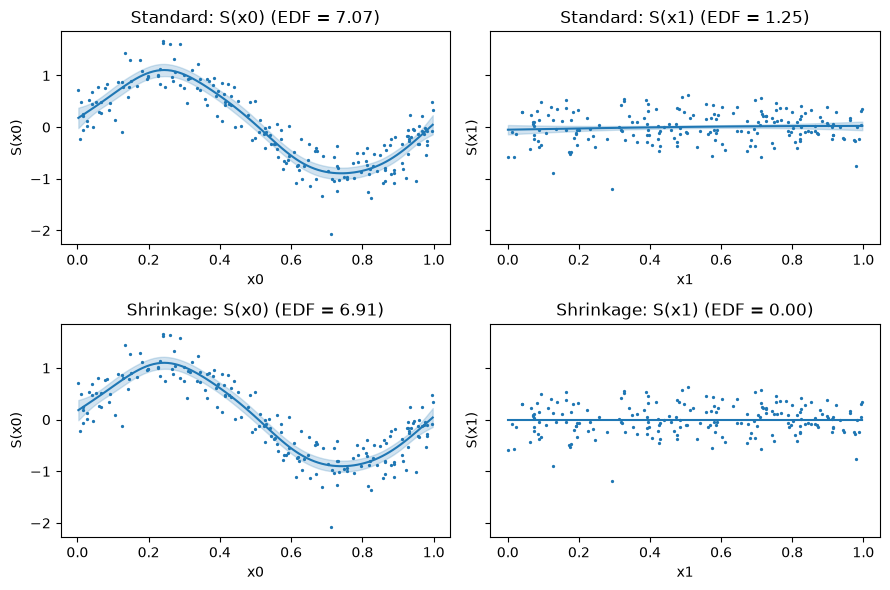

In [2]:
shrinkage = ThinPlateSpline(shrinkage=True)
models = {
    "Standard": GAM({"y": S("x0") + S("x1")}),
    "Shrinkage": GAM({"y": S("x0", bs=shrinkage) + S("x1", bs=shrinkage)}),
}

fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey=True)
for row, (name, gam) in zip(axes, models.items(), strict=True):
    gam.fit(data)
    edf = gam.edf()
    smooths = gam.predictors["y"][:2]  # The last term is the intercept
    for ax, term in zip(row, smooths, strict=True):
        gplt.continuous_1d(term=term, gam=gam, data=data, ax=ax, residuals=True)
        term_edf = edf.filter(like=term.mgcv_identifier()).sum()
        ax.set_title(f"{name}: {term.label()} (EDF = {term_edf:.2f})")
fig.tight_layout()
plt.show()

Both models find the same effect of `x0`. For the irrelevant `x1`, the standard
smooth is shrunk to a straight line, but it still uses about one degree of freedom for
its slope. The shrinkage smooth reduces the effect of `x1` to essentially zero, with an
EDF close to zero.

!!! tip

    - [`CubicSpline(shrinkage=True)`][pymgcv.basis_functions.CubicSpline] is the
      shrinkage version of the cubic regression spline.
    - Alternatively, `select=True` in [`GAM.fit`][pymgcv.gam.GAM.fit] adds an extra
      penalty to every smooth in the model, so that each term can be shrunk to zero,
      without changing the bases.